# Image Interpolation and Geometric Transformations with OpenCV

Nine educational experiments exploring how interpolation changes pixel values and how affine transformations change image coordinates.

**Tools:** Python, OpenCV, NumPy, Matplotlib. This is a classical image-processing project; it does not train a machine-learning model.

## Input and reproducibility
The bundled `data/image.jpg` is the user-supplied JPEG, originally uploaded as `image.jpg.jfif`. Its encoded bytes are preserved unchanged; only its filename has been simplified. OpenCV reads it as grayscale for these experiments. All outputs below are regenerated from this image.

Run from the project folder using **Restart Kernel and Run All**. Set `IMAGE_PATH` below to use another image. The last section exports three showcase figures to `images/`. Code comments explain each operation.


In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Keep the notebook, generator, and data/ directory together.
IMAGE_PATH = Path("data/image.jpg")
OUTPUT_DIR = Path("images")
OUTPUT_DIR.mkdir(exist_ok=True)

img = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"Cannot read {IMAGE_PATH.resolve()}; check the image path.")
print("Input:", IMAGE_PATH)
print("Shape (height, width):", img.shape)
print("Data type:", img.dtype)


Input: data/image.jpg
Shape (height, width): (442, 692)
Data type: uint8


## 1. Nearest-neighbor interpolation


In [2]:
# Resize image to 200% using Nearest Neighbor Interpolation

nearest_img = cv2.resize(
    img,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_NEAREST
)

print("Original size:", img.shape)
print("Resized size:", nearest_img.shape)

Original size: (442, 692)
Resized size: (884, 1384)


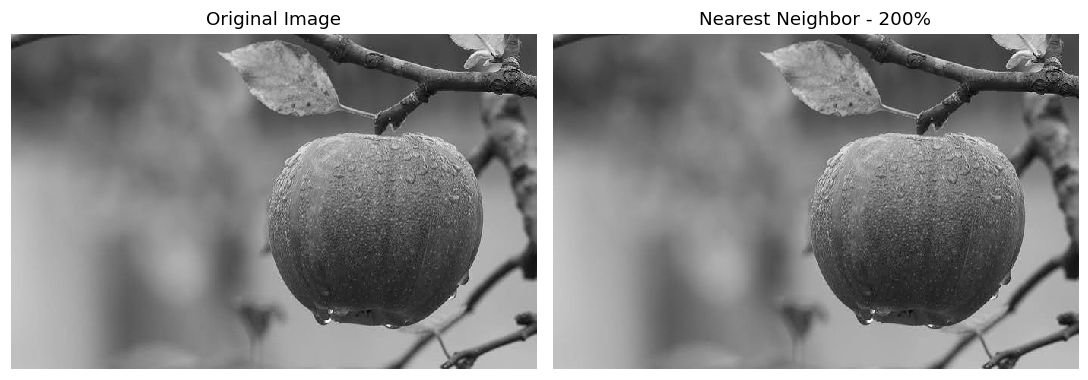

In [3]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(nearest_img, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
plt.title("Nearest Neighbor - 200%")
plt.axis("off")

plt.tight_layout()
plt.show()

**Interpretation:** Nearest neighbor replicates existing pixel values when enlarging by 2×. Width and height each double, so pixel count quadruples. Replication can produce blocky edges.


## 2. Bilinear interpolation


Original image size: (442, 692)
Bilinear resized image size: (884, 1384)


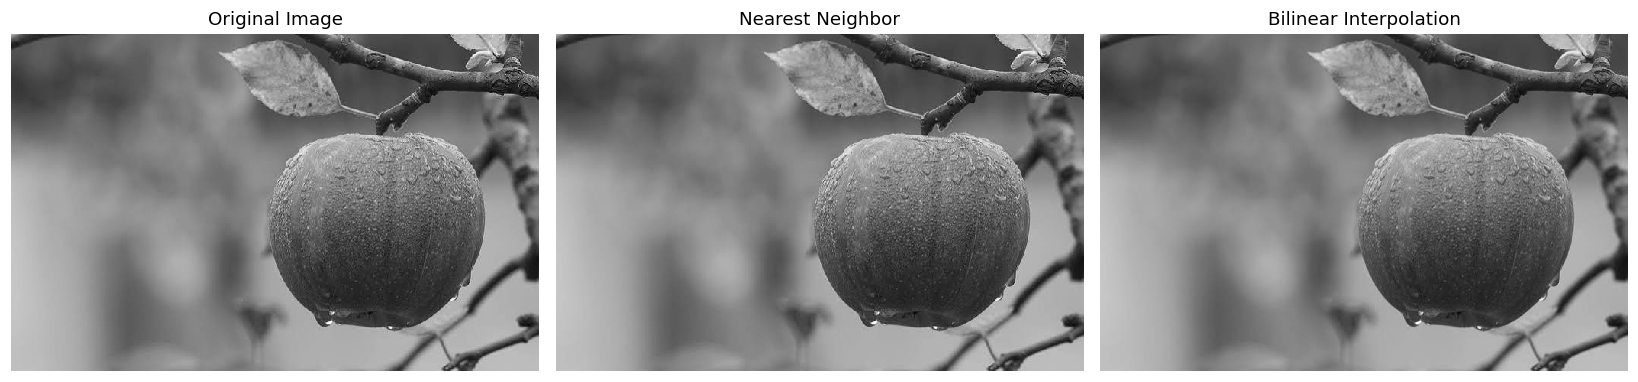

In [4]:
# TASK 2: BILINEAR INTERPOLATION

# Resize the original grayscale image by a factor of 2
# fx=2 doubles the width of the image
# fy=2 doubles the height of the image
# INTER_LINEAR tells OpenCV to use Bilinear Interpolation
bilinear_img = cv2.resize(
    img,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_LINEAR
)

# Print dimensions to confirm that the image has been enlarged
print("Original image size:", img.shape)
print("Bilinear resized image size:", bilinear_img.shape)


# Create a figure for displaying the images
plt.figure(figsize=(15, 5))

# Display the original image
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Original Image")
plt.axis("off")


# Display the Nearest Neighbor result from Task 1
# This allows us to visually compare it with Bilinear Interpolation
plt.subplot(1, 3, 2)
plt.imshow(nearest_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Nearest Neighbor")
plt.axis("off")


# Display the Bilinear Interpolation result
plt.subplot(1, 3, 3)
plt.imshow(bilinear_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Bilinear Interpolation")
plt.axis("off")


# Automatically adjust spacing between the images
plt.tight_layout()

# Show all three images
plt.show()

**Interpretation:** Bilinear interpolation blends nearby samples. It often looks smoother than nearest neighbor, but smoothing can soften edges.


## 3. Bicubic interpolation


Original image size: (442, 692)
Bicubic resized image size: (884, 1384)


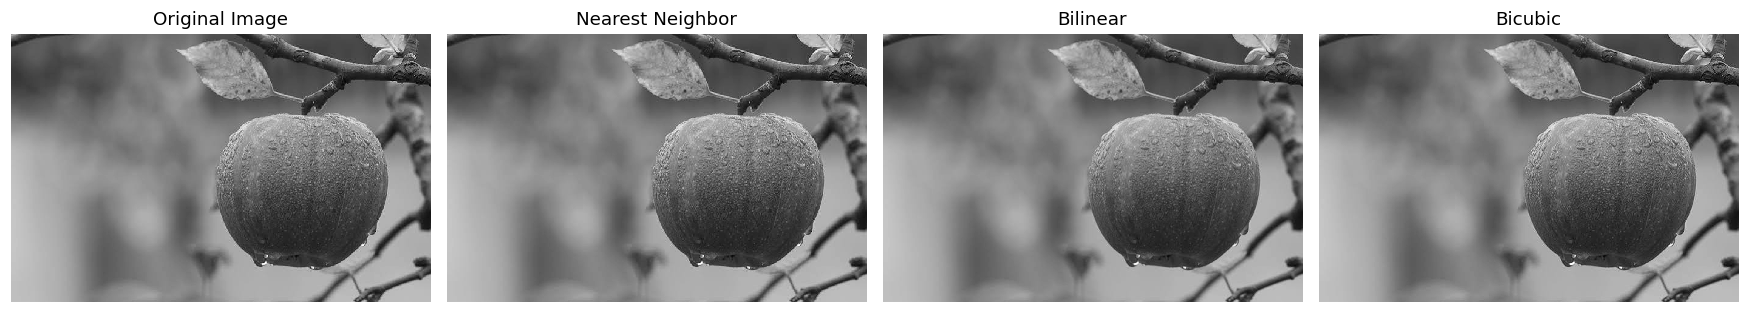

In [5]:
# TASK 3: BICUBIC INTERPOLATION

# Resize the original image by a factor of 2
# fx=2 doubles the width
# fy=2 doubles the height
# INTER_CUBIC tells OpenCV to use Bicubic Interpolation
bicubic_img = cv2.resize(
    img,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_CUBIC
)

# Print the dimensions to verify that the image
# has been enlarged to twice its original size
print("Original image size:", img.shape)
print("Bicubic resized image size:", bicubic_img.shape)


# Create a figure large enough to compare all four images
plt.figure(figsize=(16, 5))


# Display the original image
plt.subplot(1, 4, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Original Image")
plt.axis("off")


# Display the Nearest Neighbor result from Task 1
plt.subplot(1, 4, 2)
plt.imshow(nearest_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Nearest Neighbor")
plt.axis("off")


# Display the Bilinear result from Task 2
plt.subplot(1, 4, 3)
plt.imshow(bilinear_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Bilinear")
plt.axis("off")


# Display the Bicubic result
plt.subplot(1, 4, 4)
plt.imshow(bicubic_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Bicubic")
plt.axis("off")


# Adjust the spacing between all displayed images
plt.tight_layout()

# Display the final comparison
plt.show()

**Interpretation:** Bicubic interpolation uses a larger neighborhood. It may preserve apparent edge sharpness better than bilinear interpolation, but can introduce ringing. It does not recover missing scene detail.


## 4. Translation


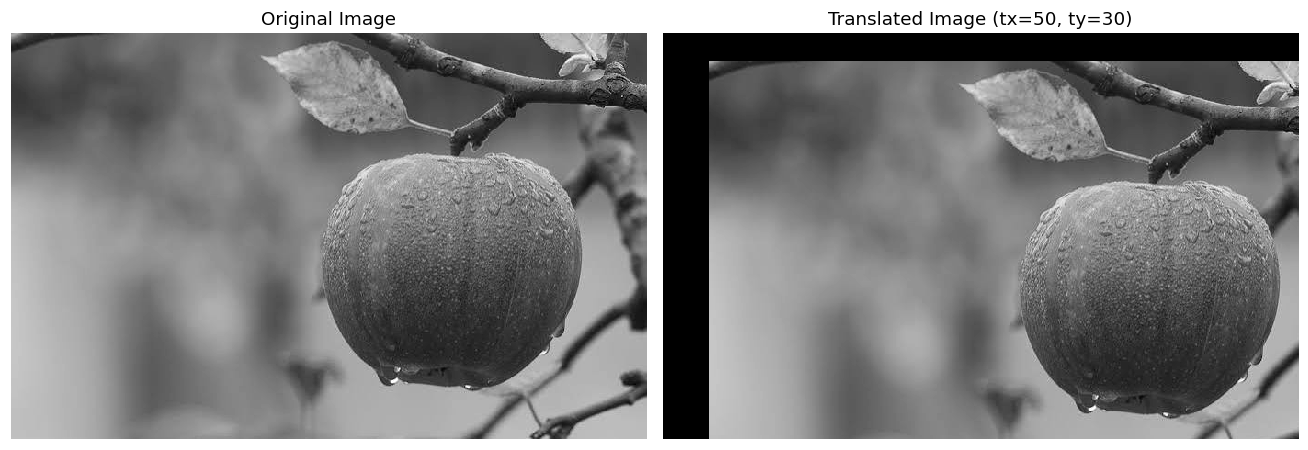

In [6]:
# TASK 4: IMAGE TRANSLATION

# Get the height and width of the original image
# img.shape returns (height, width) for a grayscale image
height, width = img.shape


# Create the translation matrix
# The matrix has the following form:
# [1  0  tx]
# [0  1  ty]
#
# tx = 50 means move the image 50 pixels to the right
# ty = 30 means move the image 30 pixels downward
translation_matrix = np.float32([
    [1, 0, 50],
    [0, 1, 30]
])


# Apply the translation transformation
# warpAffine() moves each pixel according to the translation matrix
# (width, height) keeps the output image the same size as the original
translated_img = cv2.warpAffine(
    img,
    translation_matrix,
    (width, height)
)


# Create a figure to compare the original and translated images
plt.figure(figsize=(12, 5))


# Display the original image
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Original Image")
plt.axis("off")


# Display the translated image
plt.subplot(1, 2, 2)
plt.imshow(translated_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Translated Image (tx=50, ty=30)")
plt.axis("off")


# Adjust spacing between the images
plt.tight_layout()

# Display both images
plt.show()

**Interpretation:** The image moves 50 pixels right and 30 pixels down. The canvas stays fixed: content outside it is clipped and newly exposed regions are filled with zero (black).


## 5. Non-uniform scaling


Original image size: (442, 692)
Scaled image size: (221, 1038)


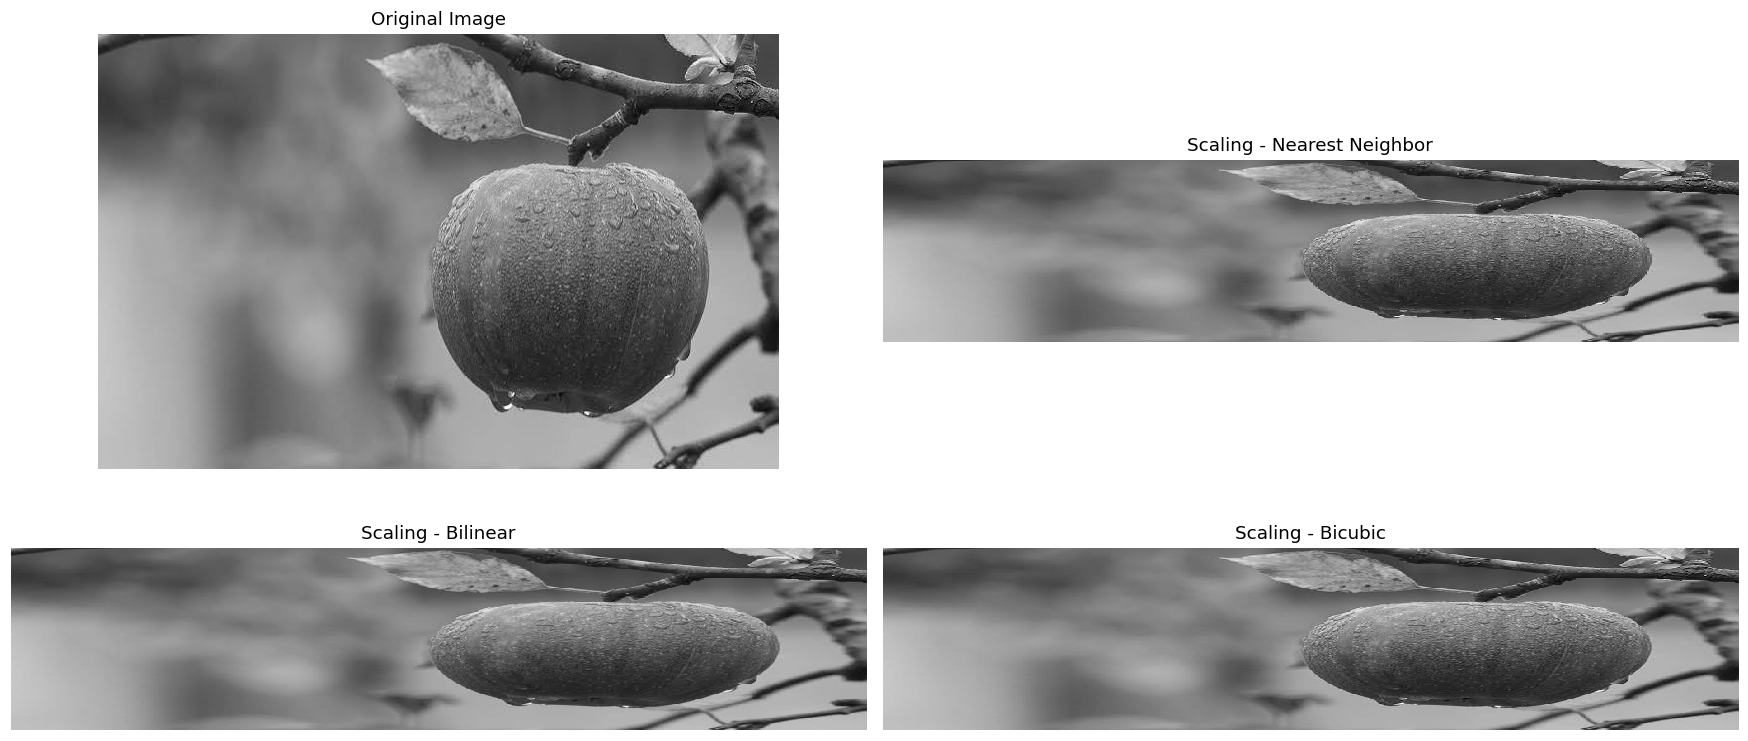

In [7]:
# TASK 5: IMAGE SCALING

# Define the scaling factors
# sx = 1.5 means the width will become 1.5 times the original width
# sy = 0.5 means the height will become half of the original height
sx = 1.5
sy = 0.5


# Scale the image using Nearest Neighbor Interpolation
# INTER_NEAREST selects the nearest existing pixel value
# It is fast but may produce pixelated or jagged results
scaled_nearest = cv2.resize(
    img,
    None,
    fx=sx,
    fy=sy,
    interpolation=cv2.INTER_NEAREST
)


# Scale the image using Bilinear Interpolation
# INTER_LINEAR calculates new pixels using the surrounding pixels
# It generally produces a smoother result than nearest neighbor
scaled_bilinear = cv2.resize(
    img,
    None,
    fx=sx,
    fy=sy,
    interpolation=cv2.INTER_LINEAR
)


# Scale the image using Bicubic Interpolation
# INTER_CUBIC uses a larger neighborhood of pixels
# It can sharpen apparent edges but may introduce ringing
scaled_bicubic = cv2.resize(
    img,
    None,
    fx=sx,
    fy=sy,
    interpolation=cv2.INTER_CUBIC
)


# Print image dimensions so we can verify the scaling
print("Original image size:", img.shape)
print("Scaled image size:", scaled_bilinear.shape)


# Create a figure to compare all results
plt.figure(figsize=(16, 8))


# Display the original image
plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Original Image")
plt.axis("off")


# Display image scaled using Nearest Neighbor
plt.subplot(2, 2, 2)
plt.imshow(scaled_nearest, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Scaling - Nearest Neighbor")
plt.axis("off")


# Display image scaled using Bilinear Interpolation
plt.subplot(2, 2, 3)
plt.imshow(scaled_bilinear, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Scaling - Bilinear")
plt.axis("off")


# Display image scaled using Bicubic Interpolation
plt.subplot(2, 2, 4)
plt.imshow(scaled_bicubic, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Scaling - Bicubic")
plt.axis("off")


# Adjust spacing between all plots
plt.tight_layout()

# Display the results
plt.show()

**Interpretation:** Width scales by 1.5 and height by 0.5, changing the aspect ratio. These three interpolation methods are compared for teaching; shrinking can introduce aliasing, and area resampling is another useful baseline.


## 6. Identity transformation


Are both images identical? True
Number of different pixels: 0


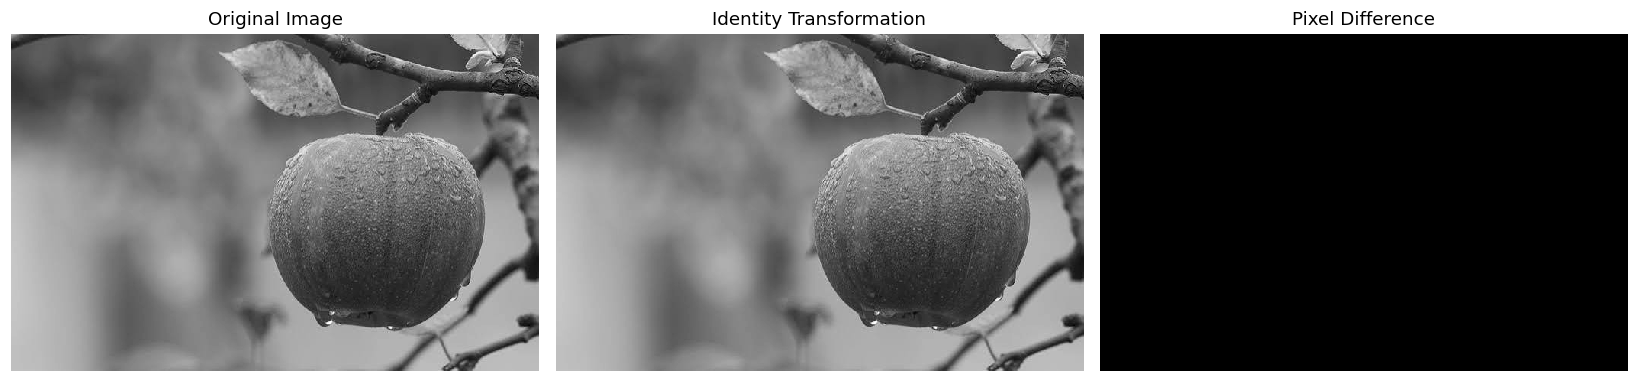

In [8]:
# TASK 6: IDENTITY TRANSFORMATION

# Get the height and width of the original grayscale image
# img.shape returns (height, width)
height, width = img.shape


# Create the Identity Transformation matrix
#
# The identity matrix is:
# [1  0  0]
# [0  1  0]
#
# There is no translation, rotation, scaling, or shearing.
# Therefore, every pixel should remain at exactly the same position.
identity_matrix = np.float32([
    [1, 0, 0],
    [0, 1, 0]
])


# Apply the identity transformation using warpAffine()
# The transformation matrix does not change the position of any pixel
# (width, height) keeps the output dimensions equal to the original image
identity_img = cv2.warpAffine(
    img,
    identity_matrix,
    (width, height)
)


# Compare the original and transformed images pixel-by-pixel
# np.array_equal() returns True only if:
# 1. Both arrays have the same dimensions
# 2. Every corresponding pixel has exactly the same value
are_identical = np.array_equal(img, identity_img)

print("Are both images identical?", are_identical)


# Calculate the absolute difference between the two images
# If the identity transformation worked correctly,
# every pixel in this difference image should have a value of 0
difference = cv2.absdiff(img, identity_img)

# Count how many pixels have different intensity values
different_pixels = np.count_nonzero(difference)

print("Number of different pixels:", different_pixels)


# Create a figure to visually compare the images
plt.figure(figsize=(15, 5))


# Display the original image
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Original Image")
plt.axis("off")


# Display the image after identity transformation
plt.subplot(1, 3, 2)
plt.imshow(identity_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Identity Transformation")
plt.axis("off")


# Display the difference image
# A completely black image means the difference is zero everywhere
plt.subplot(1, 3, 3)
plt.imshow(difference, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Pixel Difference")
plt.axis("off")


# Adjust spacing between plots
plt.tight_layout()

# Display all results
plt.show()

**Interpretation:** An identity transform should leave every pixel unchanged. The equality check and difference image verify this directly.


## 7. Rotation


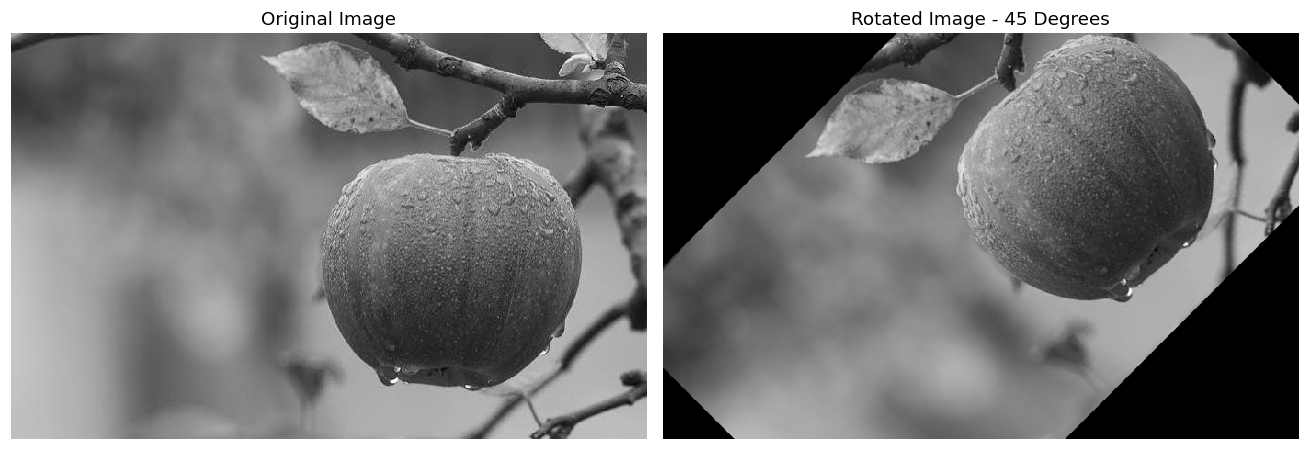

In [9]:
# TASK 7: IMAGE ROTATION

# Get the height and width of the original grayscale image
height, width = img.shape


# Find the center point of the image
# Rotation will take place around this point
center = ((width - 1) / 2.0, (height - 1) / 2.0)


# Define the rotation angle
# Positive angles in OpenCV rotate the image counterclockwise
angle = 45


# Define the scaling factor
# 1.0 means keep the original image size/scale
scale = 1.0


# Create the rotation matrix
# getRotationMatrix2D() requires:
# 1. Center of rotation
# 2. Rotation angle
# 3. Scaling factor
rotation_matrix = cv2.getRotationMatrix2D(
    center,
    angle,
    scale
)


# Apply the rotation to the image
# warpAffine() transforms the pixels according to the rotation matrix
# (width, height) keeps the output canvas the same size as the original
#
# INTER_LINEAR uses bilinear interpolation to calculate pixel values
# when rotated pixels fall between exact pixel coordinates
rotated_img = cv2.warpAffine(
    img,
    rotation_matrix,
    (width, height),
    flags=cv2.INTER_LINEAR
)


# Display the original and rotated images side by side
plt.figure(figsize=(12, 5))


# Display original image
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Original Image")
plt.axis("off")


# Display the image rotated by 45 degrees
plt.subplot(1, 2, 2)
plt.imshow(rotated_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Rotated Image - 45 Degrees")
plt.axis("off")


# Adjust spacing between the images
plt.tight_layout()

# Display the final result
plt.show()

**Interpretation:** Positive 45° rotation is counterclockwise in OpenCV. The output canvas remains fixed, so corners may be cropped. Unfilled regions are black.


## 8. Horizontal and vertical shearing


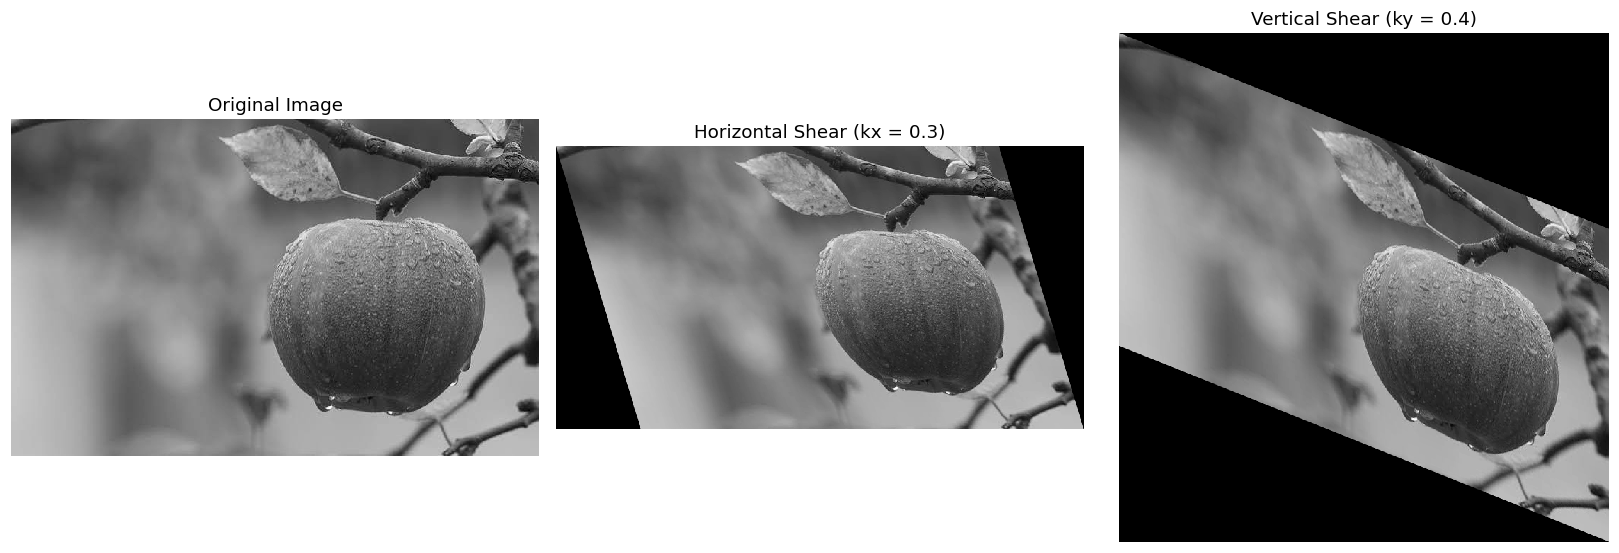

In [10]:
# TASK 8: IMAGE SHEARING

# Get the height and width of the original grayscale image
height, width = img.shape


# --------------------------------------------------
# HORIZONTAL SHEARING
# --------------------------------------------------

# Define the horizontal shear factor
# kx = 0.3 means each row is shifted horizontally
# depending on its vertical (y) position
kx = 0.3

# Create the horizontal shear transformation matrix
#
# Matrix:
# [1   kx   0]
# [0   1    0]
#
# This changes the x-coordinate while keeping
# the y-coordinate unchanged
horizontal_shear_matrix = np.float32([
    [1, kx, 0],
    [0, 1, 0]
])

# Horizontal shearing can make the image extend beyond
# its original width, so calculate a larger output width
new_width = int(np.ceil(width + kx * (height - 1)))

# Apply horizontal shearing using warpAffine()
horizontal_shear = cv2.warpAffine(
    img,
    horizontal_shear_matrix,
    (new_width, height)
)


# --------------------------------------------------
# VERTICAL SHEARING
# --------------------------------------------------

# Define the vertical shear factor
# ky = 0.4 means each column is shifted vertically
# depending on its horizontal (x) position
ky = 0.4

# Create the vertical shear transformation matrix
#
# Matrix:
# [1    0   0]
# [ky   1   0]
#
# This changes the y-coordinate while keeping
# the x-coordinate unchanged
vertical_shear_matrix = np.float32([
    [1, 0, 0],
    [ky, 1, 0]
])

# Vertical shearing can make the image extend beyond
# its original height, so calculate a larger output height
new_height = int(np.ceil(height + ky * (width - 1)))

# Apply vertical shearing using warpAffine()
vertical_shear = cv2.warpAffine(
    img,
    vertical_shear_matrix,
    (width, new_height)
)


# --------------------------------------------------
# DISPLAY RESULTS
# --------------------------------------------------

# Create a figure to compare the original image
# with horizontal and vertical shearing
plt.figure(figsize=(15, 5))


# Display the original image
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Original Image")
plt.axis("off")


# Display horizontally sheared image
plt.subplot(1, 3, 2)
plt.imshow(horizontal_shear, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Horizontal Shear (kx = 0.3)")
plt.axis("off")


# Display vertically sheared image
plt.subplot(1, 3, 3)
plt.imshow(vertical_shear, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Vertical Shear (ky = 0.4)")
plt.axis("off")


# Adjust spacing between plots
plt.tight_layout()

# Display all images
plt.show()

**Interpretation:** Horizontal shear follows x′ = x + 0.3y; vertical shear follows y′ = y + 0.4x. Expanded canvases accommodate these positive factors. Negative factors would also require a translation offset to preserve content.


## 9. Reflection


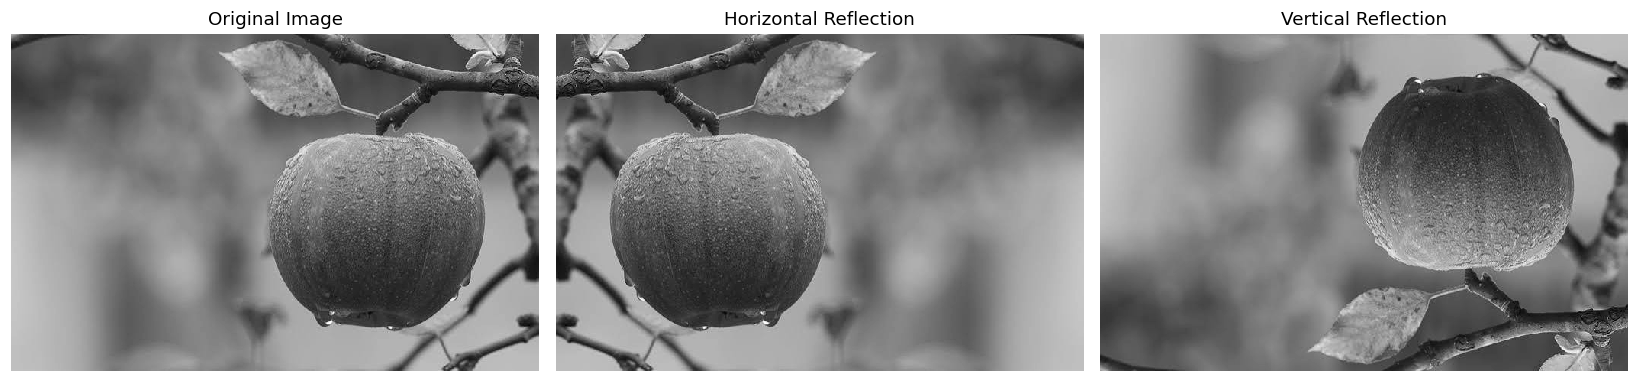

In [11]:
# TASK 9: IMAGE REFLECTION / FLIPPING


# --------------------------------------------------
# HORIZONTAL REFLECTION
# --------------------------------------------------

# Flip the image horizontally using cv2.flip()
#
# flipCode = 1 means horizontal flipping
# The left side moves to the right and
# the right side moves to the left.
#
# This creates a mirror-like version of the image.
horizontal_reflection = cv2.flip(img, 1)


# --------------------------------------------------
# VERTICAL REFLECTION
# --------------------------------------------------

# Flip the image vertically using cv2.flip()
#
# flipCode = 0 means vertical flipping
# The top of the image moves to the bottom and
# the bottom moves to the top.
vertical_reflection = cv2.flip(img, 0)


# --------------------------------------------------
# DISPLAY RESULTS
# --------------------------------------------------

# Create a figure to compare the original image
# with horizontal and vertical reflections
plt.figure(figsize=(15, 5))


# Display the original image
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Original Image")
plt.axis("off")


# Display the horizontally reflected image
plt.subplot(1, 3, 2)
plt.imshow(horizontal_reflection, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Horizontal Reflection")
plt.axis("off")


# Display the vertically reflected image
plt.subplot(1, 3, 3)
plt.imshow(vertical_reflection, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Vertical Reflection")
plt.axis("off")


# Adjust spacing between all displayed images
plt.tight_layout()

# Display the results
plt.show()

**Interpretation:** Horizontal reflection reverses columns; vertical reflection reverses rows. Flipping twice in the same direction should restore the input exactly.


## Validation
These checks verify dimensions, exact identity/reflection behavior, and the retained region after integer translation. They do not establish that one interpolation method is universally best.


In [12]:
# Confirm that every enlargement doubles height and width.
height, width = img.shape
for enlarged in (nearest_img, bilinear_img, bicubic_img):
    assert enlarged.shape == (2 * height, 2 * width)
assert np.array_equal(img, identity_img)
assert np.count_nonzero(difference) == 0
assert np.array_equal(cv2.flip(horizontal_reflection, 1), img)
assert np.array_equal(cv2.flip(vertical_reflection, 0), img)
assert translated_img.shape == img.shape
# An integer shift preserves the part that remains inside the canvas.
if height > 30 and width > 50:
    assert np.array_equal(translated_img[30:, 50:], img[:-30, :-50])
print("PASS: enlargement sizes, identity, double reflections, translation dimensions and retained pixels")
print("Identity difference pixels:", int(np.count_nonzero(difference)))
print("Non-uniform scaling shape:", scaled_bilinear.shape)


PASS: enlargement sizes, identity, double reflections, translation dimensions and retained pixels
Identity difference pixels: 0
Non-uniform scaling shape: (221, 1038)


## Export figures for GitHub and LinkedIn
All panels use the same grayscale range and nearest-neighbor display rendering, avoiding extra display smoothing. The interpolation panel shows matching crops to make pixel-level differences visible.


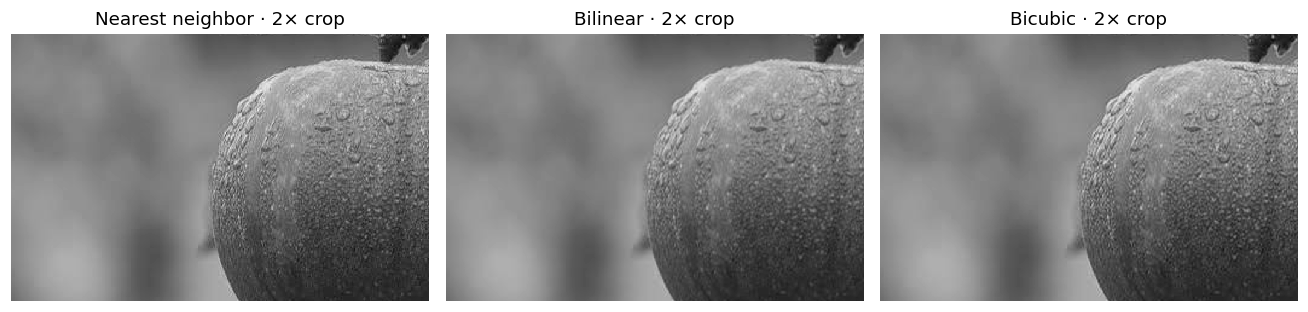

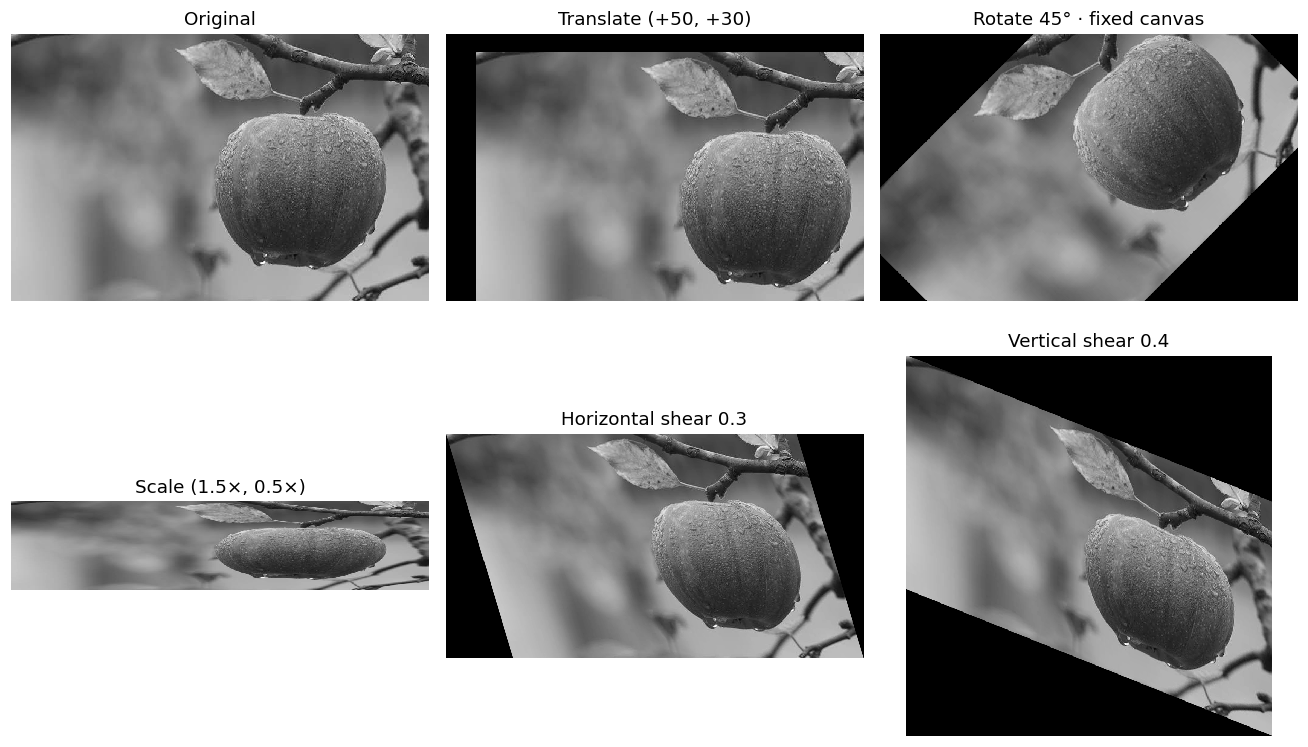

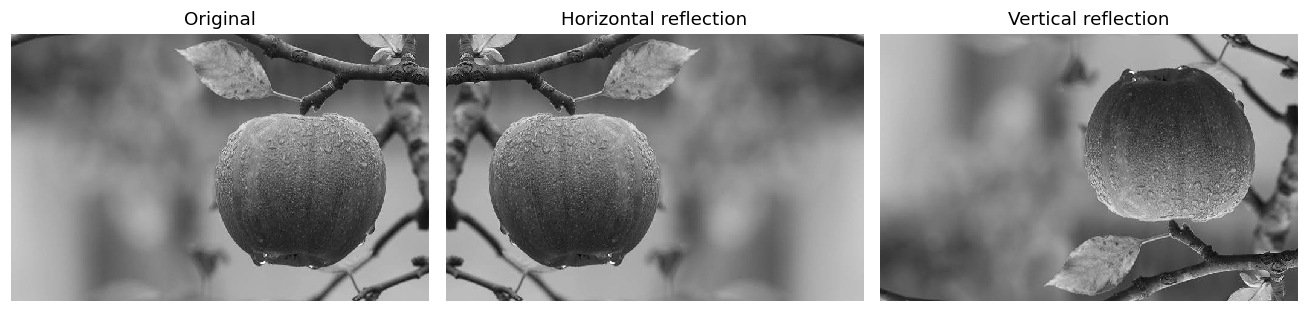

Saved three showcase PNGs to /workspace/scratch/cc64d13d21a2/interpolation_work/image-transformations-opencv/images


In [13]:
def export_panels(arrays, titles, filename, columns=3):
    # Keep equal pixel aspect ratios so geometric changes stay visible.
    rows = int(np.ceil(len(arrays) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.6 * rows), squeeze=False)
    for ax, array, title in zip(axes.flat, arrays, titles):
        ax.imshow(array, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")
    for ax in list(axes.flat)[len(arrays):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

# Compare matching central regions of the three enlarged images.
h2, w2 = nearest_img.shape
crop = np.s_[h2 // 4:3 * h2 // 4, w2 // 4:3 * w2 // 4]
export_panels([nearest_img[crop], bilinear_img[crop], bicubic_img[crop]],
              ["Nearest neighbor · 2× crop", "Bilinear · 2× crop", "Bicubic · 2× crop"],
              "interpolation_comparison.png")
export_panels([img, translated_img, rotated_img, scaled_bilinear, horizontal_shear, vertical_shear],
              ["Original", "Translate (+50, +30)", "Rotate 45° · fixed canvas", "Scale (1.5×, 0.5×)",
               "Horizontal shear 0.3", "Vertical shear 0.4"], "geometric_transformations.png")
export_panels([img, horizontal_reflection, vertical_reflection],
              ["Original", "Horizontal reflection", "Vertical reflection"], "reflection_comparison.png")
print("Saved three showcase PNGs to", OUTPUT_DIR.resolve())


## Conclusions and limitations

- Interpolation estimates output intensities; it does not recreate unknown high-resolution detail.
- Translation and rotation illustrate clipping on fixed-size canvases.
- Non-uniform scaling changes aspect ratio; shearing changes angles while preserving parallel lines before rasterization.
- Identity and double-reflection checks confirm exact pixel behavior.
- Results use one supplied image and illustrate mechanisms, not performance on a diverse dataset. No model accuracy or speed benchmark is claimed.

Reference: [OpenCV geometric transformations tutorial](https://docs.opencv.org/4.x/da/d6e/tutorial_py_geometric_transformations.html).
